<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/> 

# Statistics for machine learning
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>

## Workshop Reference Sheet
We recommend that you bring this resource with you to the workshop as it contains some of the key terms and code used to help you feel more comfortable.

### What to expect

In this workshop you will apply scientific methods for data analysis such as defining a hypothesis test, calculating significance values and interpreting the results which is an essential skill to think more like a Data Scientist and make better informed decisions based on data and communicate findings more convincingly.

### Key Terms

|   Term | Definition         | 
|:-------|:--------------|
| Hypothesis | A tentative explanation or prediction that is based on limited evidence and is subject to further testing and verification, usually denoted H. |
| Null hypothesis | A hypothesis, usually denoted H0, which assumes there is no effect or relationship in the population being studied. |
| Alternative hypothesis | An alternative hypothesis, usually denoted H1, which assumes that there is an effect or relationship in the population being studied. |
| t-test | A statistical hypothesis test that is used to determine whether the means of two groups of data are significantly different from each other. |
| Population | The entire group of individuals, objects, or events that a researcher is interested in studying. |
| Data distribution | The way in which the values of a dataset are arranged or spread out across a range of possible values. |
| Normal distribution | A continuous probability distribution characterized by a bell-shaped curve, with the majority of the data points clustered around the mean (average) and gradually decreasing in frequency as they move away from the mean. |
| Statistical significance | A statistics term used to determine whether a result is likely to be caused by chance or by a real effect in the population being studied. |
| p-value | The probability of obtaining a result as extreme or more extreme than the observed result, assuming the null hypothesis is true, this measure determines the statistical significance of a result. |

### Key Python Statements

|   Statement | Definition         | Example      |
|-------:|:--------------|:----------|
|      `numpy` | A library that provides a multidimensional array object and an extensive library of mathematical functions for working with arrays. | `import numpy as np` |
|      `pandas` | A library that provides easy-to-use data structures and data manipulation tools for efficient data analysis and cleaning. | `import pandas as pd` |
|      `seaborn` | A popular data visualization library that is built on top of matplotlib. | `import seaborn as sns` |
|      `arange` | A numpy function that returns an array of evenly spaced values within a specified range, with a specified stepsize. | `np.arange(0, 5, 2)` # outputs array([0, 2, 4]) |
|      `corr` | A method provided by the Pandas library that is used to compute the pairwise correlation of columns in a Pandas DataFrame. | `df.corr()` |
|      `groupby` | A method used for grouping data in a Pandas DataFrame or Series based on one or more categorical variables. | `df.groupby('category_column')` |
|      `append` | A built-in method for lists and other sequence types, which allows you to add an element to the end of the sequence. | `list.append(item)` |
| `concatenate` | A numpy function that allows you to join two or more arrays of the same shape along a specified axis. | `np.concatenate((array1, array2), axis=0)` |
| `random` | A numpy module that provides various functions to generate random numbers and arrays. | `from numpy.random import normal` |
| `normal` | A function from Numpy's random module used to generate a random sample from a normal distribution. | `np.random.normal()` |
| `choice` | A function from Numpy's random module used to generate random samples from a given array or sequence. | `np.random.choice()` |
| `where` | A function from Numpy's random module used to return the indices of elements in an input array or to replace elements in an array that satisfy a given condition. | `np.random.where(my_array > 5, 1, 0)` # Elements > 5 replaced with 1 and <= 5 replaced with 0. |
| `scipy`| A library for scientific computing providing a wide range of mathematical algorithms and functions for various scientific and engineering applications. | `from scipy.stats import ttest_ind`  |
| `ttest_ind`| A function from Scipy's stats module used to perform an independent two-sample t-test. |`ttest_ind(A,B).pvalue`|

## Challenge 1: The Log-Transform Revenue Bug

**Scenario:**
You are analysing user transaction data for a mobile game. The product manager wants to know the "average spend per user" to project next month's revenue. 

You are given a dataset with 500 transaction amounts. 

If you report the arithmetic mean, the product manager will severely overestimate typical user spending due to a massive outlier (a "whale" who spent $5000). 

**Your Task:**
1. Calculate the standard arithmetic mean.
2. Apply a natural log transformation (`np.log1p`) to the data.
3. Calculate the mean of the transformed data.
4. Transform that mean back to the original scale using the exponential function (`np.expm1`). 
5. Compare the arithmetic mean to this "log-transformed mean". Which is a better representation of the typical user?

In [6]:
import numpy as np

# Raw data
# generate a numpy array of 500 transactions, where the first 490 transactions are between 1 and 5, and the last 10 transactions are between 1000 and 5000
transactions = np.concatenate((np.random.randint(1, 6, size=490), np.random.randint(1000, 5001, size=10)))

# Your code here:

### Solution 1 

In [7]:
# 1. Arithmetic Mean
arithmetic_mean = np.mean(transactions)
print(f"Arithmetic Mean: ${arithmetic_mean:.2f}")

# 2 & 3. Log Transform and calculate new mean
log_data = np.log1p(transactions) 
log_mean = np.mean(log_data)

# 4. Transform back to original scale
typical_spend = np.expm1(log_mean)
print(f"Typical Spend (Log-Transformed Mean): ${typical_spend:.2f}")

# The typical spend is much closer to $2, which accurately reflects the vast majority of users.

Arithmetic Mean: $54.66
Typical Spend (Log-Transformed Mean): $3.27


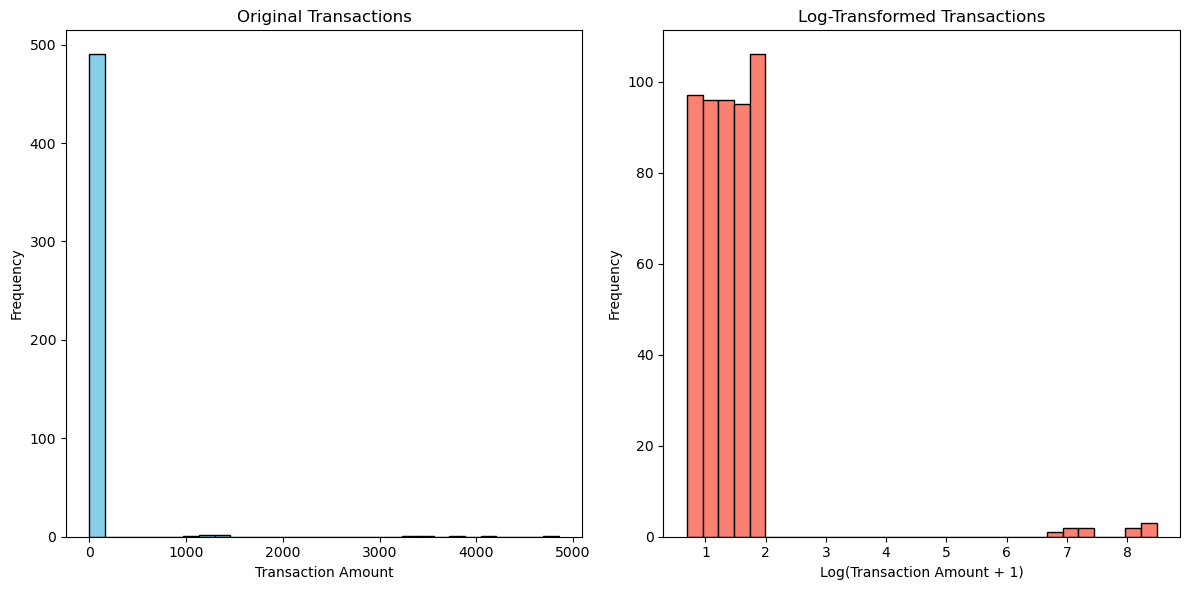

In [8]:
# present a visualization of the data
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(transactions, bins=30, color='skyblue', edgecolor='black')
plt.title('Original Transactions')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.subplot(1, 2, 2)
plt.hist(log_data, bins=30, color='salmon', edgecolor='black')
plt.title('Log-Transformed Transactions')
plt.xlabel('Log(Transaction Amount + 1)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

## Challenge Exercise 2: The Policy Nudge Illusion 

**Scenario:**
You are a Data Scientist working for the government's Behavioral Insights Team (the "Nudge Unit"). You are running an A/B test on a new tax reminder letter to encourage on-time payments. 
* **Letter A (Standard)** was sent to 1,000 citizens and achieved a **54%** on-time payment rate.
* **Letter B (Behavioral Nudge)** was sent to 1,000 citizens and achieved a **76%** on-time payment rate.

The Minister is thrilled and wants to roll out Letter B nationally. However, you suspect a confounding variable: **Taxpayer Type** (Large Businesses vs. Freelancers). 

**Your Task:**
Run the provided cell to generate the raw pandas dataframe simulating the trial. Use `pandas` `groupby()` operations to calculate the compliance rate for Letter A and Letter B, but split by **both** `Letter` and `Taxpayer_Type`. 

What do you discover? Should the government roll out Letter B?

In [3]:
import pandas as pd

# Simulating the hidden data
df = pd.DataFrame({
    'Letter': ['A']*100 + ['A']*900 + ['B']*900 + ['B']*100,
    'Taxpayer_Type': ['Large Business']*100 + ['Freelancer']*900 + ['Large Business']*900 + ['Freelancer']*100,
    'Paid_On_Time': [1]*90 + [0]*10 + [1]*450 + [0]*450 + [1]*720 + [0]*180 + [1]*40 + [0]*60
})

# Your code here:

### Solution 2 

In [4]:
# 1. Verify aggregate compliance rates (Letter B looks vastly superior)
overall_rates = df.groupby('Letter')['Paid_On_Time'].mean() * 100
print("Overall On-Time Payment Rates:")
print(overall_rates)
print("-" * 30)

# 2. Unmask Simpson's Paradox by grouping by Taxpayer Type AND Letter
segmented_rates = df.groupby(['Taxpayer_Type', 'Letter'])['Paid_On_Time'].mean() * 100
print("Segmented On-Time Payment Rates:")
print(segmented_rates)

# CONCLUSION: 
# Letter A is actually better for Freelancers (50% vs 40%).
# Letter A is actually better for Large Businesses (90% vs 80%).
# Letter B only won the overall average because it was disproportionately sent to 
# Large Businesses, who naturally pay on time at much higher rates than Freelancers. 
# The trial was poorly randomized. Letter A is the true winner!

Overall On-Time Payment Rates:
Letter
A    54.0
B    76.0
Name: Paid_On_Time, dtype: float64
------------------------------
Segmented On-Time Payment Rates:
Taxpayer_Type   Letter
Freelancer      A         50.0
                B         40.0
Large Business  A         90.0
                B         80.0
Name: Paid_On_Time, dtype: float64
